# Short indels: would the Truvari event collapse change anything?

Companion to `truvari_event_collapse_sensitivity.ipynb` (SVs). Currently **short indels are analysed as records, one
unit per panel record**; events exist only for SVs (> 50 bp). This notebook asks what the same collapse would do to
the **simple insertions and deletions of 1-50 bp** (MNPs and complex records excluded), so we can decide whether to
extend events to them.

Same method, same code (`_build_event_map.truvari_events`, via `truvari_sweep_indels.py`): inside each pangenome
bubble (recovered from the symbolic IDs, as for SVs) and per type, two records merge if size similarity >= **pctsize**,
sequence similarity >= **pctseq** (edit distance on the inserted / deleted sequence) and `|POS_A - POS_B|` <= **refdist**;
greedy, keep first. Default 0.95 / 0.95 / 500 bp.

**Why short indels need their own look.** For a 1-bp insertion the inserted sequence is a single base, so *any* two
insertions of the same base inside one bubble have identical sequence and equal size: the only thing left to separate
two different variants is `refdist`. With the SV default of 500 bp they can merge falsely. The `refdist` panel and the
size-band breakdown below are about exactly that.

In [1]:

import glob, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
G = "/global/scratch/projects/fc_moilab/tbellg/kmate/analysis/grenenet_selection"; SA = "/global/scratch/projects/fc_moilab/tbellg/kmate/analysis/grenenet_selection/r1_sv_negative_selection/results/sv_adaptive"; PLOTS = f"{G}/notebooks/plots"
sys.path.insert(0, f"{G}/genes/convergence")
import plot_theme as TH
TH.apply(); plt.rcParams['figure.dpi'] = 120
from matplotlib.colors import LinearSegmentedColormap
GREENRAMP = LinearSegmentedColormap.from_list('g', ['#CFE8CF', '#8CC98C', '#3F9B49', '#1B5E20'])
sw = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f"{SA}/truvari_sweep_indels_Chr*.csv"))], ignore_index=True)
print("chromosomes:", sorted(sw.chrom.unique()))
num = [c for c in sw.columns if c.startswith(('events_', 'records_')) or c in ('n_events','n_ins','n_del','n_records','n_bubbles','seconds')]
key = ['factor','pctseq','pctsize','refdist','keep']
tot = sw.groupby(key, as_index=False)[num].sum()
tot['_o'] = (tot.factor != 'default').astype(int)       # the default setting is also a grid / refdist point: keep one copy
tot = tot.sort_values('_o').drop_duplicates(['pctseq','pctsize','refdist','keep']).drop(columns='_o').reset_index(drop=True)
N_REC, N_BUB = int(tot.n_records.iloc[0]), int(tot.n_bubbles.iloc[0])
tot['records_per_event'] = N_REC / tot.n_events
d = tot[(tot.pctseq==0.95)&(tot.pctsize==0.95)&(tot.refdist==500)&(tot.keep=='first')].iloc[0]
print(f"{N_REC:,} simple indel records in {N_BUB:,} bubble units (singletons count as a unit)")
print(f"DEFAULT 0.95/0.95/500: {int(d.n_events):,} events = {d.records_per_event:.3f} records per event; "
      f"{100*(1 - d.n_events/N_REC):.1f}% of records merged into another")


chromosomes: ['Chr1', 'Chr2', 'Chr3', 'Chr4', 'Chr5']
1,402,975 simple indel records in 749,936 bubble units (singletons count as a unit)
DEFAULT 0.95/0.95/500: 1,294,591 events = 1.084 records per event; 7.7% of records merged into another


## Collapse by size band and by position limit (`refdist`)

In [2]:

# % of records merged, by size band, at the default and at tighter position limits
BANDS = [('1','1 bp'), ('2_5','2-5 bp'), ('6_20','6-20 bp'), ('21_50','21-50 bp')]
rows = []
for r in (0, 1, 5, 20, 50, 500):
    t = tot[(tot.factor.isin(['refdist','default'])) & (tot.refdist==r) & (tot.pctseq==0.95) & (tot.pctsize==0.95) & (tot.keep=='first')].iloc[0]
    row = {'refdist (bp)': r, 'all': round(100*(1 - t.n_events/t.n_records), 1)}
    for n, lab in BANDS: row[lab] = round(100*(1 - t[f'events_{n}']/t[f'records_{n}']), 1)
    row['events'] = int(t.n_events); rows.append(row)
print("% of records merged into another record (pctseq = pctsize = 0.95), by size band")
pd.DataFrame(rows).set_index('refdist (bp)')


% of records merged into another record (pctseq = pctsize = 0.95), by size band


,all,1 bp,2-5 bp,6-20 bp,21-50 bp,events
refdist (bp),,,,,,
0,1.5,0.0,0.0,3.2,15.9,1381540
1,1.7,0.1,0.1,3.5,16.6,1378809
5,2.0,0.6,0.2,3.6,16.7,1375190
20,2.6,1.7,0.5,3.7,16.8,1365855
50,3.5,3.2,0.7,3.8,16.9,1354396
500,7.7,11.4,1.6,3.8,16.9,1294591


## Sensitivity: position limit, pctseq x pctsize, run time

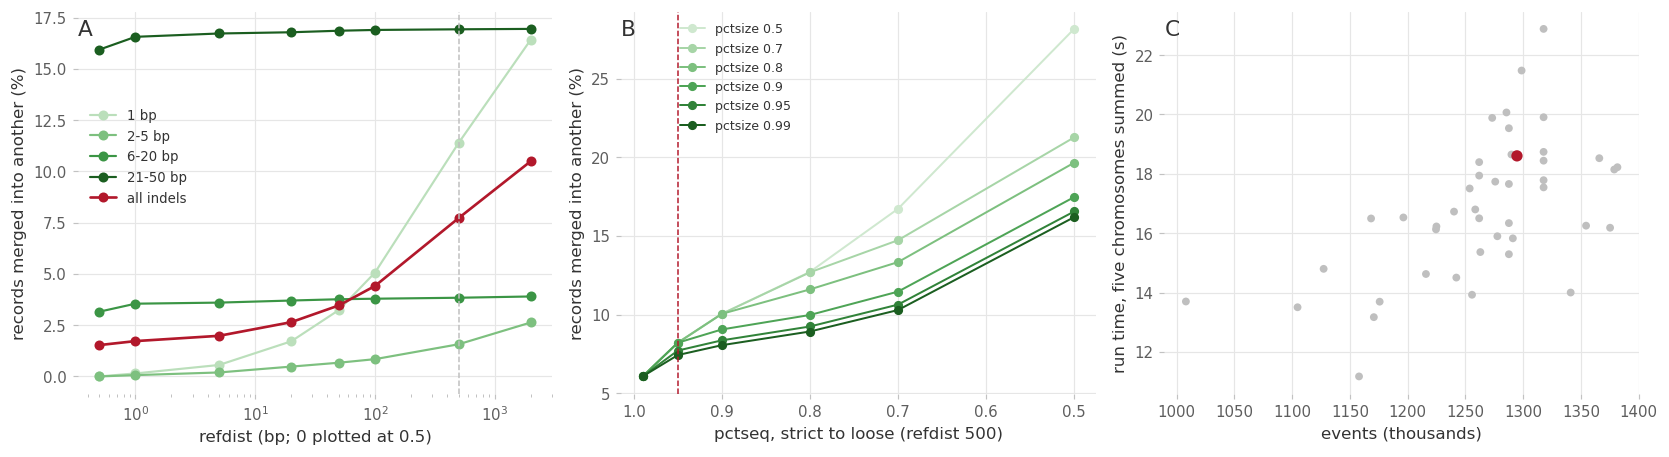

,factor,pctseq,pctsize,refdist,keep,n_events,n_ins,n_del,records_per_event,seconds
0,default,0.95,0.95,500,first,1294591,559188,735403,1.084,18.606
12,keep,0.95,0.95,500,common,1291030,557355,733675,1.087,15.828
13,refdist,0.95,0.95,0,first,1381540,591382,790158,1.016,18.223
14,refdist,0.95,0.95,1,first,1378809,589750,789059,1.018,18.146
15,refdist,0.95,0.95,5,first,1375190,588022,787168,1.020,16.185
16,refdist,0.95,0.95,20,first,1365855,584325,781530,1.027,18.527
17,refdist,0.95,0.95,50,first,1354396,580331,774065,1.036,16.255
18,refdist,0.95,0.95,100,first,1341077,575685,765392,1.046,14.002
43,refdist,0.95,0.95,2000,first,1255693,544541,711152,1.117,13.927


In [3]:

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
r = tot[(tot.factor.isin(['refdist','default'])) & (tot.pctseq==0.95) & (tot.pctsize==0.95) & (tot.keep=='first')].sort_values('refdist')
cols = GREENRAMP(np.linspace(0.1, 1.0, 4))
x = r.refdist.replace(0, 0.5)
for (n, lab), c in zip(BANDS, cols):
    axes[0].plot(x, 100*(1 - r[f'events_{n}']/r[f'records_{n}']), marker='o', ms=5, lw=1.3, color=c, label=lab)
axes[0].plot(x, 100*(1 - r.n_events/N_REC), marker='o', ms=5, lw=1.6, color=TH.ACCENT, label='all indels')
axes[0].set_xscale('log'); axes[0].set_xlabel('refdist (bp; 0 plotted at 0.5)'); axes[0].set_ylabel('records merged into another (%)')
axes[0].axvline(500, color=TH.FAINT, ls='--', lw=0.9); axes[0].legend(loc='center left', bbox_to_anchor=(0.0, 0.62))
a = tot[(tot.factor.isin(['grid','default'])) & (tot.refdist==500) & (tot.keep=='first')]
P = a.pivot(index='pctseq', columns='pctsize', values='n_events').sort_index(ascending=False).sort_index(axis=1)
for c, z in zip(GREENRAMP(np.linspace(0, 1, P.shape[1])), P.columns):
    axes[1].plot(P.index, 100*(1 - P[z]/N_REC), marker='o', ms=4.5, lw=1.2, color=c, label=f'pctsize {z}')
axes[1].invert_xaxis(); axes[1].axvline(0.95, color=TH.ACCENT, lw=0.9, ls='--')
axes[1].set_xlabel('pctseq, strict to loose (refdist 500)'); axes[1].set_ylabel('records merged into another (%)'); axes[1].legend(loc='upper left', bbox_to_anchor=(0.1, 1.0), fontsize=7.5)
dd = tot[tot.factor=='default'].iloc[0]
axes[2].scatter(tot.n_events/1000, tot.seconds, s=22, color=TH.FAINT, edgecolor='none')
axes[2].scatter(dd.n_events/1000, dd.seconds, s=46, color=TH.ACCENT, edgecolor='none')
axes[2].set_xlabel('events (thousands)'); axes[2].set_ylabel('run time, five chromosomes summed (s)')
for ax, l in zip(axes, 'ABC'): TH.panel(ax, l)
fig.tight_layout(); fig.savefig(f"{PLOTS}/truvari_indel_sensitivity.png", dpi=200); plt.show()
tot[tot.factor.isin(['refdist','keep','default'])][['factor','pctseq','pctsize','refdist','keep','n_events','n_ins','n_del','records_per_event','seconds']].round(3)


## Is `refdist` binding? POS spread inside a bubble

136,754 (bubble, type) groups with >= 2 indel records
count    136754.0
mean        317.0
std        2479.0
min           0.0
50%           1.0
75%          10.0
90%         288.0
99%        6689.0
max       99835.0
  groups whose records span > 0 bp: 50.9%
  groups whose records span > 5 bp: 29.1%
  groups whose records span > 50 bp: 16.0%
  groups whose records span > 500 bp: 7.6%


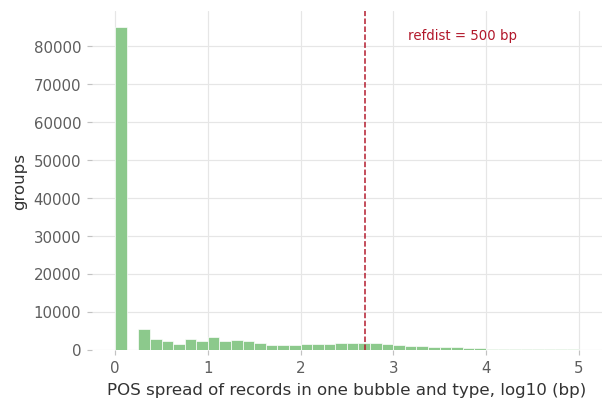

In [4]:

pr = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f"{SA}/truvari_indel_bubble_pos_range_Chr*.csv"))], ignore_index=True)
print(f"{len(pr):,} (bubble, type) groups with >= 2 indel records")
print(pr.pos_range_bp.describe(percentiles=[.5,.75,.9,.99]).round(0).to_string())
for t in (0, 5, 50, 500): print(f"  groups whose records span > {t} bp: {100*(pr.pos_range_bp > t).mean():.1f}%")
fig, ax = plt.subplots(figsize=(5.2, 3.5))
ax.hist(np.log10(pr.pos_range_bp.clip(lower=1)), bins=40, color=TH.GREENS[0], edgecolor='white', linewidth=0.4)
ax.axvline(np.log10(500), color=TH.ACCENT, lw=0.9, ls='--'); TH.note(ax, 'refdist = 500 bp', y=0.95, x=0.62, color=TH.ACCENT)
ax.set_xlabel('POS spread of records in one bubble and type, log10 (bp)'); ax.set_ylabel('groups')
fig.tight_layout(); fig.savefig(f"{PLOTS}/truvari_indel_bubble_pos_range.png", dpi=200); plt.show()


## Site-frequency spectrum: records vs events

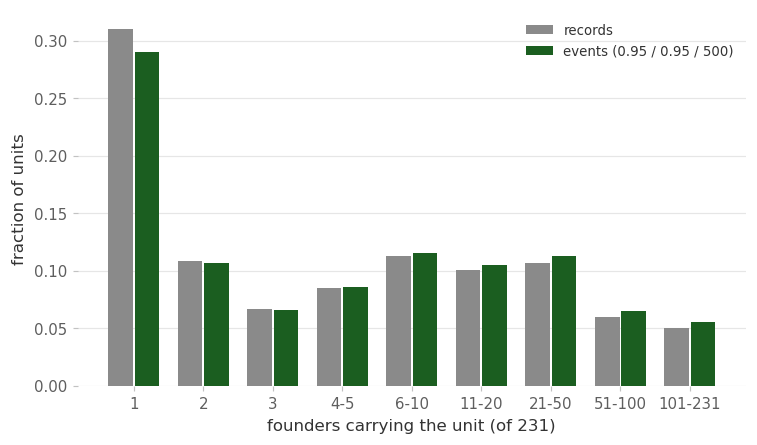

,n_units,singleton_frac,median_carriers,common_ge_10pct
unit,,,,
alleles,1402975,0.31,4.0,0.204
events,1294591,0.29,4.0,0.220


In [5]:

sf = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f"{SA}/indel_sfs_alleles_vs_events_Chr*.csv"))], ignore_index=True)
EDGES = [1, 2, 3, 4, 6, 11, 21, 51, 101, 232]
LAB = ['1','2','3','4-5','6-10','11-20','21-50','51-100','101-231']
sf['bin'] = pd.cut(sf.carriers, EDGES, right=False, labels=LAB)
frac = sf.groupby(['unit','bin'], observed=False).size().unstack(0); frac = frac / frac.sum()
fig, ax = plt.subplots(figsize=(6.4, 3.8)); x = np.arange(len(LAB)); w = 0.38
ax.bar(x - w/2, frac['alleles'].values, w*0.94, color=TH.MUTED, label='records', linewidth=0)
ax.bar(x + w/2, frac['events'].values, w*0.94, color=TH.GREENS[2], label='events (0.95 / 0.95 / 500)', linewidth=0)
TH.grid_only(ax, 'y'); ax.set_xticks(x); ax.set_xticklabels(LAB); ax.legend(loc='upper right')
ax.set_xlabel('founders carrying the unit (of 231)'); ax.set_ylabel('fraction of units')
fig.tight_layout(); fig.savefig(f"{PLOTS}/truvari_indel_sfs_records_vs_events.png", dpi=200); plt.show()
sf.groupby('unit').agg(n_units=('carriers','size'), singleton_frac=('carriers', lambda v: (v==1).mean()),
        median_carriers=('carriers','median'), common_ge_10pct=('carriers', lambda v: (v>=23).mean())).round(3)
